# 6. Geometric PDEs: Curvature, Diffusion and Level Sets

Practice for week 6: the gradient is normal to level lines, `div(∇I / |∇I|)` measures curvature (1/r for a
circle), heat equation vs total-variation diffusion on a noisy edge, and curve evolution with level sets
(constant velocity and curvature motion).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 6.1 The gradient is perpendicular to the level lines

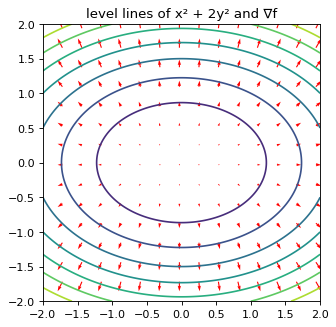

In [2]:
y, x = np.mgrid[-2:2:200j, -2:2:200j]
f = x ** 2 + 2 * y ** 2
gy, gx = np.gradient(f)
plt.figure(figsize=(4.5, 4.5))
plt.contour(x, y, f, 10, cmap="viridis")
s = slice(None, None, 14)
plt.quiver(x[s, s], y[s, s], gx[s, s], gy[s, s], color="r", scale=4)
plt.gca().set_aspect("equal"); plt.title("level lines of x² + 2y² and ∇f"); plt.show()

## 6.2 Curvature of the level lines

For the signed distance to a circle of radius r, `κ = div(∇I / |∇I|)` evaluated on the circle should be
`1 / r`. Straight lines have zero curvature; circles are the only closed curves with constant curvature.

In [3]:
def curvature(u, eps=1e-8):
    uy, ux = np.gradient(u)
    mag = np.sqrt(ux ** 2 + uy ** 2) + eps
    return np.gradient(ux / mag, axis=1) + np.gradient(uy / mag, axis=0)

yy, xx = np.mgrid[:200, :200].astype(float)
for r in [10, 20, 40, 80]:
    d = np.hypot(xx - 100, yy - 100) - r
    k = curvature(d)[np.abs(d) < 0.5]
    print(f"r = {r:3d}: measured curvature {k.mean():.4f}, 1/r = {1 / r:.4f}")
d_line = xx - 100.0
print(f"straight line: curvature {np.abs(curvature(d_line)).max():.1e}")

r =  10: measured curvature 0.0990, 1/r = 0.1000
r =  20: measured curvature 0.0500, 1/r = 0.0500
r =  40: measured curvature 0.0250, 1/r = 0.0250
r =  80: measured curvature 0.0125, 1/r = 0.0125
straight line: curvature 0.0e+00


## 6.3 Heat equation vs total variation

Minimizing `∫ |∇I|^p` by gradient descent gives `I_t = div(|∇I|^(p−2) ∇I)`. With p = 2 it is the heat
equation (isotropic diffusion), which smooths noise and the edge equally. With p = 1 (total variation) the
diffusion is only along the level lines and stops across strong edges. Both are run until the noise is
reduced to about the same level; TV keeps much more of the edge. (Run TV for long and the step itself
slowly loses contrast too.)

noisy        : noise std in flat part 0.081, jump between pixels 63 and 64: 0.597 (true 0.6)
heat (p = 2) : noise std in flat part 0.013, jump between pixels 63 and 64: 0.134 (true 0.6)
TV (p = 1)   : noise std in flat part 0.014, jump between pixels 63 and 64: 0.471 (true 0.6)


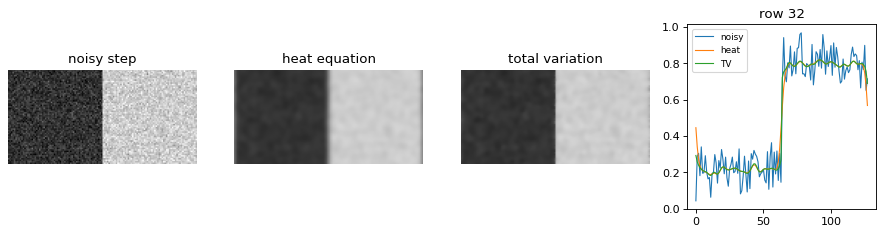

In [4]:
step = np.where(np.arange(128) < 64, 0.2, 0.8)[None].repeat(64, 0)
noisy = step + rng.normal(0, 0.08, step.shape)

def lap(u):
    return np.roll(u, 1, 0) + np.roll(u, -1, 0) + np.roll(u, 1, 1) + np.roll(u, -1, 1) - 4 * u

def tv_step(u, dt=0.01, eps=0.05):
    ux = np.roll(u, -1, 1) - u; uy = np.roll(u, -1, 0) - u
    mag = np.sqrt(ux ** 2 + uy ** 2 + eps ** 2)
    px, py = ux / mag, uy / mag
    return u + dt * (px - np.roll(px, 1, 1) + py - np.roll(py, 1, 0))

heat = noisy.copy()
for _ in range(8): heat = heat + 0.2 * lap(heat)
tv = noisy.copy()
for _ in range(10): tv = tv_step(tv)

flat = (slice(None), slice(10, 50))
for name, u in [("noisy", noisy), ("heat (p = 2)", heat), ("TV (p = 1)", tv)]:
    jump = u[:, 64].mean() - u[:, 63].mean()
    print(f"{name:13s}: noise std in flat part {u[flat].std():.3f}, jump between pixels 63 and 64: {jump:.3f} (true 0.6)")

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for a, u, t in zip(axes[:3], [noisy, heat, tv], ["noisy step", "heat equation", "total variation"]):
    a.imshow(u, cmap="gray", vmin=0, vmax=1); a.set_title(t); a.axis("off")
for u, t in [(noisy, "noisy"), (heat, "heat"), (tv, "TV")]:
    axes[3].plot(u[32], label=t, lw=1)
axes[3].legend(fontsize=8); axes[3].set_title("row 32")
plt.show()

## 6.4 Level-set curve evolution

A curve is the zero level set of a function `f` (negative inside). Moving the curve with normal speed `v`
becomes `f_t = v |∇f|`, so topology and corners are handled for free.

* Constant speed, `f_t = |∇f|`: the curve moves inward at unit speed. Concave parts of the star pinch and
  corners appear.
* Curvature motion, `f_t = κ |∇f|`: convex bumps move in fast, concave dents move out, and the star
  rounds into a circle before it shrinks to a point.

Moving points along the curve (tangential velocity) does not change the shape, so only the normal speed
enters these equations.

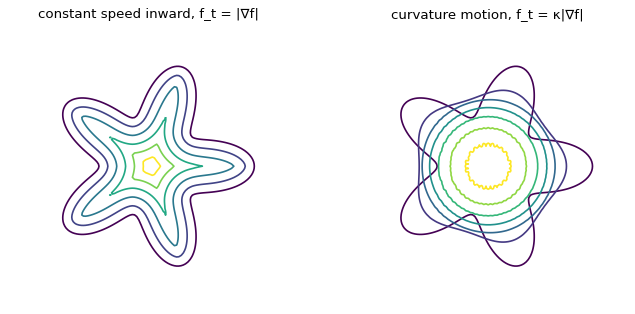

In [5]:
th = np.arctan2(yy[:128, :128] - 64, xx[:128, :128] - 64)
rr = np.hypot(xx[:128, :128] - 64, yy[:128, :128] - 64)
star = rr - (35 + 12 * np.cos(5 * th))

def grad_mag_upwind(f):
    # Osher–Sethian upwind |∇f| for an inward-moving front (f_t = +|∇f|)
    dxp = np.roll(f, -1, 1) - f; dxm = f - np.roll(f, 1, 1)
    dyp = np.roll(f, -1, 0) - f; dym = f - np.roll(f, 1, 0)
    return np.sqrt(np.maximum(dxp, 0) ** 2 + np.minimum(dxm, 0) ** 2 + np.maximum(dyp, 0) ** 2 + np.minimum(dym, 0) ** 2)

def curvature_motion(f, eps=1e-6):
    fy, fx = np.gradient(f); fyy, fyx = np.gradient(fy); fxy, fxx = np.gradient(fx)
    return (fxx * fy ** 2 - 2 * fx * fy * fxy + fyy * fx ** 2) / (fx ** 2 + fy ** 2 + eps)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
f = star.copy()
for it in range(41):
    if it % 8 == 0: axes[0].contour(f, [0], colors=[plt.cm.viridis(it / 40)])
    f = f + 0.5 * grad_mag_upwind(f)
axes[0].set_title("constant speed inward, f_t = |∇f|")
f = star.copy()
for it in range(3001):
    if it % 500 == 0: axes[1].contour(f, [0], colors=[plt.cm.viridis(it / 3000)])
    f = f + 0.2 * curvature_motion(f)
axes[1].set_title("curvature motion, f_t = κ|∇f|")
for a in axes: a.set_aspect("equal"); a.invert_yaxis(); a.axis("off")
plt.show()